# setup + imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import json

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [49]:
from sklearn.metrics import matthews_corrcoef

In [2]:
train_data = pd.read_csv('obsidian_train.csv')
test_data = pd.read_csv('obsidian_test.csv')

In [3]:
senzors = train_data[['sensor_x', 'sensor_y']]

# data exploration


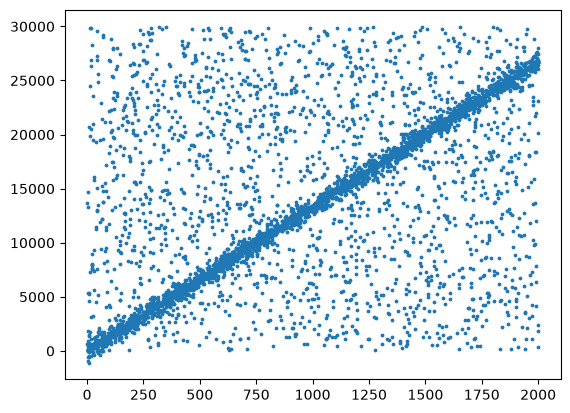

In [12]:
P = PCA(n_components=2).fit_transform(senzors)
plt.scatter(senzors['sensor_x']**2 + senzors['sensor_y']**2, train_data['flux_energy'], s=3)


(array([1.60e+01, 1.90e+01, 1.60e+01, 2.10e+01, 1.80e+01, 2.30e+01,
        1.30e+01, 1.90e+01, 2.40e+01, 2.00e+01, 1.70e+01, 2.00e+01,
        1.70e+01, 2.50e+01, 1.80e+01, 1.70e+01, 1.80e+01, 1.30e+01,
        1.80e+01, 2.10e+01, 2.40e+01, 2.00e+01, 1.70e+01, 2.20e+01,
        1.70e+01, 2.40e+01, 2.50e+01, 2.30e+01, 1.90e+01, 2.50e+01,
        2.30e+01, 2.20e+01, 2.70e+01, 2.80e+01, 2.30e+01, 3.20e+01,
        3.40e+01, 4.30e+01, 4.70e+01, 5.20e+01, 5.60e+01, 9.70e+01,
        1.64e+02, 3.52e+02, 6.48e+03, 3.56e+02, 1.94e+02, 1.11e+02,
        6.70e+01, 4.70e+01, 4.00e+01, 2.40e+01, 2.90e+01, 1.80e+01,
        2.50e+01, 2.20e+01, 2.10e+01, 1.90e+01, 1.80e+01, 1.30e+01,
        1.20e+01, 1.30e+01, 1.30e+01, 1.00e+01, 1.10e+01, 1.80e+01,
        1.30e+01, 1.00e+01, 6.00e+00, 1.50e+01, 6.00e+00, 9.00e+00,
        1.60e+01, 1.50e+01, 1.00e+01, 7.00e+00, 1.10e+01, 1.10e+01,
        1.60e+01, 1.20e+01, 6.00e+00, 1.30e+01, 7.00e+00, 7.00e+00,
        0.00e+00, 6.00e+00, 1.40e+01, 8.00e+00, 

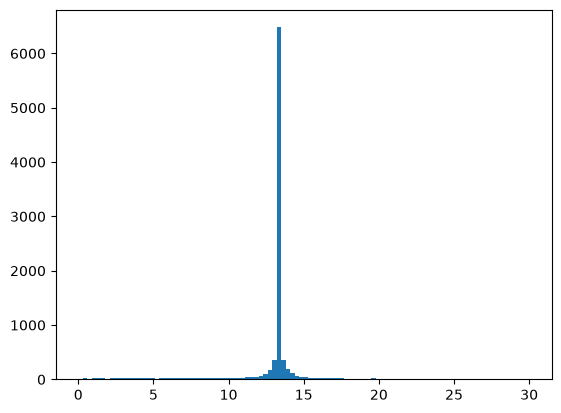

In [16]:
r2 = train_data['sensor_x']**2 + train_data['sensor_y']**2
ratio = train_data['flux_energy'] / r2

plt.hist(ratio, bins=100, range=(0, 30))

(array([6.086e+03, 9.200e+01, 1.140e+02, 9.000e+01, 8.800e+01, 1.090e+02,
        9.600e+01, 8.300e+01, 8.600e+01, 9.300e+01, 8.200e+01, 7.200e+01,
        8.900e+01, 7.000e+01, 7.100e+01, 6.000e+01, 6.000e+01, 5.800e+01,
        6.400e+01, 5.400e+01, 5.700e+01, 3.600e+01, 5.000e+01, 3.900e+01,
        2.500e+01, 3.300e+01, 3.100e+01, 4.200e+01, 2.400e+01, 2.900e+01,
        2.800e+01, 1.700e+01, 1.600e+01, 1.400e+01, 2.000e+01, 1.500e+01,
        1.500e+01, 1.700e+01, 9.000e+00, 1.000e+01, 9.000e+00, 1.000e+01,
        3.000e+00, 7.000e+00, 5.000e+00, 4.000e+00, 4.000e+00, 8.000e+00,
        7.000e+00, 2.000e+00, 1.000e+00, 3.000e+00, 2.000e+00, 6.000e+00,
        1.100e+01, 6.000e+00, 3.000e+00, 5.000e+00, 3.000e+00, 5.000e+00,
        1.000e+00, 2.000e+00, 4.000e+00, 2.000e+00, 3.000e+00, 5.000e+00,
        4.000e+00, 2.000e+00, 3.000e+00, 3.000e+00, 4.000e+00, 5.000e+00,
        6.000e+00, 4.000e+00, 6.000e+00, 5.000e+00, 7.000e+00, 2.000e+00,
        2.000e+00, 3.000e+00, 1.000e+0

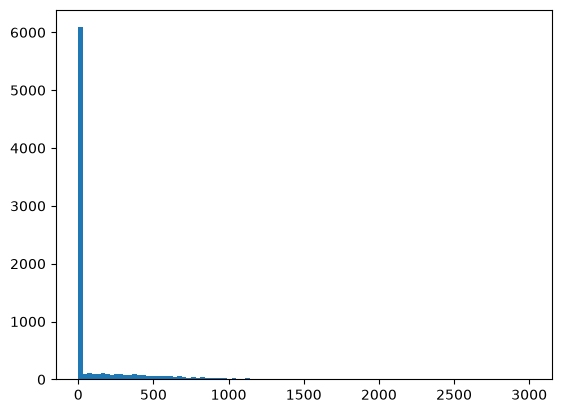

In [22]:
k = ratio.median()
dist = np.abs(train_data['flux_energy'] - k * r2)

plt.hist(dist, bins=100, range=(0, 3000))


# setting stuff up. labbeling

In [27]:
thr = 100
print(cutoff, (dist < thr).sum())

100 6328


In [28]:
train_data['label'] = (dist < cutoff).astype(int)
print(train_data['label'].value_counts())

label
1    6328
0    3672
Name: count, dtype: int64


In [29]:
canon = train_data.loc[train_data['label']==1]
echo = train_data.loc[train_data['label']==0]

print(canon)
print(echo)

     id_hex   flux_energy                              resonance_str  \
0     2E86E  17835.148887              gardsolidverianluxhelidluxlum   
4     E1069  26632.889062                                verianobsid   
5     C204B  14520.160928  aetsolobsluxhelaetidluxaetianlumianversol   
6     85BCB  26258.467707                                      gards   
8     BEC90  14760.158553                        iangardhelaethellux   
...     ...           ...                                        ...   
9992  71975  16899.641780                                aetianidlum   
9993  D151E  10990.549365                          gardgardverianobs   
9994   E71F   7941.716473                                    aetsola   
9996  4C132    722.266630                    solluxidverobslumverlum   
9999  C2D0B   8663.601225                                      aetga   

       sensor_x   sensor_y  label  
0    -30.140797  20.628435      1  
4     -0.008725 -44.631826      1  
5     28.302284 -16.881373 

In [40]:
print(np.mean(canon['resonance_str'].str.len()))
print(np.mean(canon['flux_energy']))

22.30388748419722
13448.949447315776


In [41]:
print(np.mean(echo['resonance_str'].str.len()))
print(np.mean(echo['flux_energy']))

25.579520697167755
14282.614345626513


In [42]:
print(echo['resonance_str'].head(10))

1                 echofailfailkzzvoidkzzbzzfailerrnu
2                        aetaetidaetluzmianaetianver
3                                          failzecho
7     nullxxxechovoidxxxfailxxxzrrvoidbzzkzzvoidbzzn
9                 voidxxxxxxnullbzzvoidzrrvoidzrrnul
12                                      bzzfazilerrf
14        echozrrerrechovoidkzzvoidfailerrbzzechonul
16                        zrrkzzerrechzoechovoidbzzv
17                            kzzbzzerrvoidzrrbzzbzz
19                       voidkzzxxxzrrzzrrxxxechofai
Name: resonance_str, dtype: str


In [43]:
print(canon['resonance_str'].head(10))

0                 gardsolidverianluxhelidluxlum
4                                   verianobsid
5     aetsolobsluxhelaetidluxaetianlumianversol
6                                         gards
8                           iangardhelaethellux
10              idaetluxhelgardobslumsolaetianh
11                            ianhelianianverid
13                                  aethelverlu
15                idhelidverververianaetididhel
18                                        ianhe
Name: resonance_str, dtype: str


# submission ideas

In [54]:
noise = ['void', 'null', 'nul', 'fail', 'fai', 'echo', 'err', 'xxx', 'zrr', 'bzz', 'kzz', 'zz']

def prednoise(texts):
    preds = []
    for s in texts:
        s = str(s)
        found = 0
        for w in noise:
            if w in s:
                found = 1
                break
        if found == 1:
            preds.append(0)
        else:
            preds.append(1)
    return np.array(preds)

def prim(n):
    if n < 2:
        return False
    d = 2
    while d * d <= n:
        if n % d == 0:
            return False
        d += 1
    return True

def predprime(texts):
    preds = []
    for s in texts:
        if prim(len(str(s))):
            preds.append(1)
        else:
            preds.append(0)
    return np.array(preds)
            

In [55]:
pred_train = prednoise(train_data['resonance_str'])
print(matthews_corrcoef(train_data['label'], pred_train))
print(pd.crosstab(train_data['label'], pred_train))

0.6938088601895047
col_0     0     1
label            
0      2501  1171
1       245  6083


In [56]:
pred_train = predprime(train_data['resonance_str'])
print(matthews_corrcoef(train_data['label'], pred_train))
print(pd.crosstab(train_data['label'], pred_train))

0.9323786716451775
col_0     0     1
label            
0      3672     0
1       331  5997


In [57]:
def predboth(texts):
    p_noise = prednoise(texts)
    p_prime = predprime(texts)
    preds = []
    for i in range(len(p_noise)):
        if p_noise[i] == 1 and p_prime[i] == 1:
            preds.append(1)
        else:
            preds.append(0)
    return np.array(preds)

In [58]:
pred_train = predboth(train_data['resonance_str'])
print(matthews_corrcoef(train_data['label'], pred_train))
print(pd.crosstab(train_data['label'], pred_train))

0.9323786716451775
col_0     0     1
label            
0      3672     0
1       331  5997


# submission

In [60]:
pred_test = predboth(test_data['resonance_str'])
submission = pd.DataFrame({
    'subtaskID': 1,
    'datapointID': test_data['id_hex'],
    'answer': pred_test,
})
submission.to_csv('submission.csv', index=False)